# 07 — Brand premium and value analysis

**Goal:** answer the second half of the research question. How much more (or less) does each brand charge **for the same specs**, what is each spec worth, and which phones are priced above or below what their listed specs and brand suggest?

**Which model for what**
- **Ridge** (Phase 5) is the **interpretable** model: one coefficient per brand and per spec, so it gives brand premiums and spec values directly.
- **Model A** (OLS, specs + chip, no brand; Phase 4) gives a phone's **hardware value**: what a typical phone with this hardware costs, ignoring the brand.
- **Gradient boosting** (Phase 6) is the **most accurate** model. We show its prediction next to ridge's as a second opinion.

How accurate these models are on unseen phones (Phase 7) is printed below, because every ridge-based number in this notebook is only as reliable as ridge itself.

**Project decisions that affect this notebook**
- **Apple:** Apple A-series chips are grouped with flagship Snapdragon 8 chips (`chip_group`), because otherwise the Apple chip column and the Apple brand column would be identical. So Apple's premium means *relative to a phone with a flagship chip and the same specs*.
- **Google and "Other":** the Tensor chip is used only by Google, and the Kirin chip only by Huawei (inside "Other", together with Sony). Those chips cannot be fully separated from the brands, so the Google and "Other" premiums partly include chip value.

### Setup
Libraries, the train and test phones, and the settings chosen in Phases 5–6 (`results/best_params.json`). Nothing is tuned in this notebook.

In [1]:
import sys
sys.path.insert(0, "../src")
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression, Ridge

from features import NUMERIC_FEATURES
from split import load_train_test, cv_folds

pd.set_option("display.width", 220)
CATEGORICAL = ["chip_group", "brand"]
FEATURES = NUMERIC_FEATURES + CATEGORICAL
best_params = json.load(open("../results/best_params.json"))
train, test = load_train_test(include_web_lookup=True)
print("training phones:", len(train), "| test phones:", len(test))

training phones: 558 | test phones: 144


**Accuracy on unseen phones (Phase 7 test set)**, read from `results/test_scores.csv`.

In [2]:
test_scores = pd.read_csv("../results/test_scores.csv").set_index("model")
accuracy = test_scores.loc[["Ridge", "Gradient boosting", "Model A: specs + chip"], ["R²", "median % error"]]
print(accuracy.round(3).to_string())

                          R²  median % error
model                                       
Ridge                  0.849          21.533
Gradient boosting      0.932          12.357
Model A: specs + chip  0.785          23.664


The two pipelines used in this notebook, the same as in Phases 4–7:
- **Ridge:** standardised numeric features plus **all** brand and chip dummies, α from Phase 5.
- **Model A (OLS):** numeric features plus chip dummies with the reference category (`snapdragon_other`) dropped, no brand, fitted with `LinearRegression` (identical to `fit_ols` in 03_linear_simple).

In [3]:
RIDGE_ALPHA = best_params["ridge"]["alpha"]
# The category lists are fixed to those of the full training set, so that a bootstrap resample (8.3)
# that happens to miss a rare brand or chip still has the same columns (that column is then all zeros).
CATEGORIES = [sorted(train[col].unique()) for col in CATEGORICAL]

def make_ridge():
    pre = ColumnTransformer([
        ("num", StandardScaler(), NUMERIC_FEATURES),
        ("cat", OneHotEncoder(categories=CATEGORIES, handle_unknown="ignore", sparse_output=False), CATEGORICAL)])
    return Pipeline([("pre", pre), ("model", Ridge(alpha=RIDGE_ALPHA))])

def make_model_a():
    pre = ColumnTransformer([
        ("num", "passthrough", NUMERIC_FEATURES),
        ("cat", OneHotEncoder(drop=["snapdragon_other"], handle_unknown="ignore", sparse_output=False), ["chip_group"])])
    return Pipeline([("pre", pre), ("model", LinearRegression())])

## 8.1 An out-of-sample prediction for every phone
To judge whether a phone is priced above or below what its specs suggest, we compare its actual price with a model's prediction. If the model had **seen** that phone while fitting, it would have pulled its fit towards that phone's price, so the gap (the **residual**) would look smaller than it really is, especially for unusual phones. So every phone gets a prediction from a model that did **not** see it:
- **Training phones:** **out-of-fold** predictions (each phone predicted by the model fitted on the other 4 grouped folds). Ridge and gradient boosting come from Phase 6 (`results/oof_predictions_phase6.csv`); Model A's are computed below with the same saved folds.
- **Test phones:** the Phase 7 predictions (`results/test_predictions.csv`), from models fitted on the full training set, which never saw the test phones.

In [4]:
oof_a = pd.Series(np.nan, index=train.index)
for fit_idx, val_idx in cv_folds(train):
    fit, val = train.iloc[fit_idx], train.iloc[val_idx]
    model = make_model_a().fit(fit[FEATURES], fit["log_price"])
    oof_a.iloc[val_idx] = model.predict(val[FEATURES])

oof6 = pd.read_csv("../results/oof_predictions_phase6.csv", index_col="row")
test_pred = pd.read_csv("../results/test_predictions.csv", index_col="row")

train_part = train.assign(set="train", pred_a=oof_a, pred_ridge=oof6["oof_Ridge"],
                          pred_gb=oof6["oof_Gradient boosting"])
test_part = test.assign(set="test", pred_a=test_pred["log_pred | Model A: specs + chip"],
                        pred_ridge=test_pred["log_pred | Ridge"], pred_gb=test_pred["log_pred | Gradient boosting"])
phones = pd.concat([train_part, test_part])
assert phones.index.is_unique and len(phones) == len(train) + len(test), "each phone must appear once"
assert phones[["pred_a", "pred_ridge", "pred_gb"]].notna().all().all(), "every phone needs one prediction per model"
print(f"{len(phones)} phones, each with one out-of-sample prediction from Model A, ridge and gradient boosting")

702 phones, each with one out-of-sample prediction from Model A, ridge and gradient boosting


## 8.2 Brand premium (ridge)
We fit ridge on the full training set. Because all brand dummies are kept, each brand has its own coefficient bᵦ. The coefficients only mean something **relative to each other**, so we compare each brand with the **average brand** (the plain mean of all 15 brand coefficients, each brand counting once):

**premium vs average = exp(bᵦ − mean of all brand coefficients) − 1**

For example, +30 % means: for the same specs and chip group, this brand's phones cost about 30 % more than an average brand's. Ridge's light penalty (α = 1.53) pulls the brand coefficients very slightly towards each other, so these premiums are, if anything, a little **conservative** (closer to 0 than OLS would give).

In [5]:
ridge = make_ridge().fit(train[FEATURES], train["log_price"])
names = [n.replace("num__", "").replace("cat__", "") for n in ridge.named_steps["pre"].get_feature_names_out()]
coef = pd.Series(ridge.named_steps["model"].coef_, index=names)

brand_cols = [c for c in names if c.startswith("brand_")]
brands = [c.removeprefix("brand_") for c in brand_cols]
b = coef[brand_cols].to_numpy()
premium_avg = pd.Series(100 * (np.exp(b - b.mean()) - 1), index=brands)
premium_samsung = pd.Series(100 * (np.exp(b - coef["brand_Samsung"]) - 1), index=brands)
n_train = train["brand"].value_counts()
pd.DataFrame({"premium vs average brand %": premium_avg, "vs Samsung %": premium_samsung,
              "training phones": n_train}).sort_values("premium vs average brand %", ascending=False).round(1)

,premium vs average brand %,vs Samsung %,training phones
Apple,97.3,64.5,59
Other,81.6,51.4,12
Google,57.7,31.4,17
Samsung,20.0,0.0,65
Xiaomi,8.3,-9.7,14
Vivo,-1.1,-17.6,51
Oppo,-1.8,-18.2,94
Nokia,-9.5,-24.5,7
Tecno,-11.5,-26.2,33
Motorola,-14.7,-28.9,50


## 8.3 How certain are the premiums? Grouped bootstrap of the training set
A single fit gives one number per brand, but with a different sample of phones the premiums would change. As in Phase 7, the **bootstrap** estimates how much: we draw 1,000 new training sets by resampling whole **phone models** (model groups) with replacement, so storage variants stay together, refit the same ridge pipeline (same α) on each, and recompute every premium. The 2.5th and 97.5th percentiles of the 1,000 values form a **95 % interval**.

A small brand can be missing from a resample by chance (e.g. Nokia has only 4 phone models in training). Its premium is then undefined in that resample (recorded as missing), and the "average brand" is the mean over the brands present. The same resamples also give intervals for the spec values in 8.4.

In [6]:
rng = np.random.default_rng(42)
groups = train["model_group"].unique()
rows_of = {g: np.flatnonzero(train["model_group"].to_numpy() == g) for g in groups}
boot_brand, boot_coef = [], []
for i in range(1000):
    chosen = rng.choice(groups, size=len(groups), replace=True)          # phone models, with replacement
    sample = train.iloc[np.concatenate([rows_of[g] for g in chosen])]
    fit = make_ridge().fit(sample[FEATURES], sample["log_price"])
    c = pd.Series(fit.named_steps["model"].coef_, index=names)
    scale = pd.Series(fit.named_steps["pre"].named_transformers_["num"].scale_, index=NUMERIC_FEATURES)
    present = [f"brand_{x}" for x in brands if (sample["brand"] == x).any()]
    bb = c[present] - c[present].mean()                                  # vs the average of present brands
    boot_brand.append(pd.Series(100 * (np.exp(bb) - 1)).rename(lambda s: s.removeprefix("brand_")))
    boot_coef.append(c[NUMERIC_FEATURES] / scale)                       # per original unit (e.g. per log2 GB)
boot_brand = pd.DataFrame(boot_brand).reindex(columns=brands)
boot_coef = pd.DataFrame(boot_coef)
print("resamples in which a brand was missing:", boot_brand.isna().sum()[boot_brand.isna().sum() > 0].to_dict())

resamples in which a brand was missing: {'Nokia': 13, 'Other': 1, 'Xiaomi': 2}


The interval for every brand, and next to it the premium **relative to Samsung** (ridge) with Phase 4's OLS Model B values (`results/ols_model_b_coefficients.csv`), to check that the two models agree. A brand whose interval includes 0 % cannot be distinguished from an average brand.

In [7]:
ols_b = pd.read_csv("../results/ols_model_b_coefficients.csv").set_index("term")
premiums = pd.DataFrame({
    "training phones": n_train.reindex(brands),
    "premium vs average %": premium_avg,
    "low %": boot_brand.quantile(0.025), "high %": boot_brand.quantile(0.975),
    "ridge vs Samsung %": premium_samsung,
    "OLS Model B vs Samsung %": [ols_b.loc[f"brand: {x}", "% price effect"] if x != "Samsung" else 0.0 for x in brands]})
premiums["interval includes 0"] = (premiums["low %"] <= 0) & (premiums["high %"] >= 0)
premiums = premiums.sort_values("premium vs average %", ascending=False)
premiums.round(1)

,training phones,premium vs average %,low %,high %,ridge vs Samsung %,OLS Model B vs Samsung %,interval includes 0
Apple,59,97.3,67.5,133.0,64.5,72.5,False
Other,12,81.6,45.9,109.5,51.4,78.2,False
Google,17,57.7,33.5,83.1,31.4,45.7,False
Samsung,65,20.0,5.2,38.8,0.0,0.0,False
Xiaomi,14,8.3,-6.5,23.6,-9.7,-9.5,True
Vivo,51,-1.1,-13.9,12.5,-17.6,-20.2,True
Oppo,94,-1.8,-16.2,15.2,-18.2,-19.1,True
Nokia,7,-9.5,-16.2,-1.7,-24.5,-27.5,False
Tecno,33,-11.5,-21.5,0.0,-26.2,-29.1,True
Motorola,50,-14.7,-23.6,-4.6,-28.9,-30.8,False


**Chart.** Each brand's premium vs the average brand with its 95 % interval; grey = interval includes 0 %.

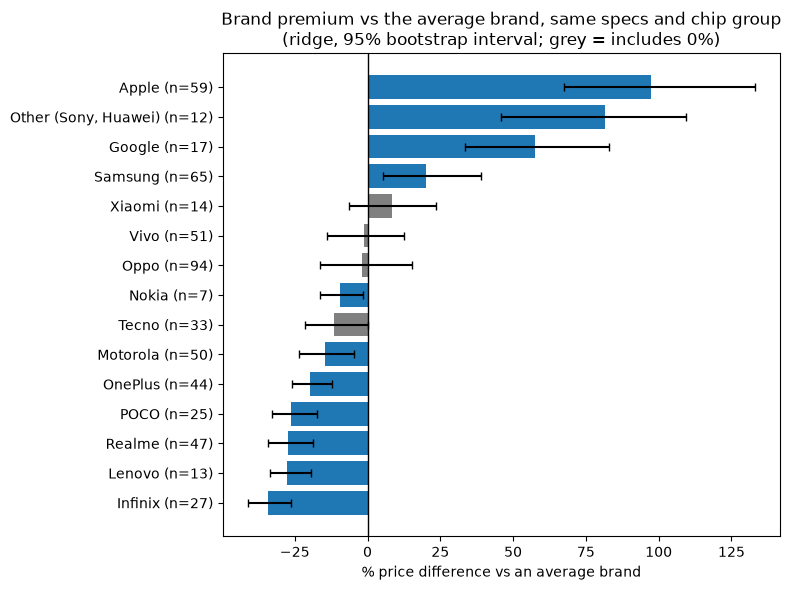

In [8]:
plot = premiums.sort_values("premium vs average %")
labels = [f"{'Other (Sony, Huawei)' if x == 'Other' else x} (n={n})" for x, n in zip(plot.index, plot["training phones"])]
colours = ["gray" if z else "tab:blue" for z in plot["interval includes 0"]]
fig, ax = plt.subplots(figsize=(8, 6))
ypos = np.arange(len(plot))
ax.barh(ypos, plot["premium vs average %"], color=colours)
ax.errorbar(plot["premium vs average %"], ypos, fmt="none", color="black", capsize=3,
            xerr=[plot["premium vs average %"] - plot["low %"], plot["high %"] - plot["premium vs average %"]])
ax.axvline(0, color="black", linewidth=1)
ax.set_yticks(ypos, labels)
ax.set(title="Brand premium vs the average brand, same specs and chip group\n(ridge, 95% bootstrap interval; grey = includes 0%)",
       xlabel="% price difference vs an average brand")
fig.tight_layout()
fig.savefig("../results/fig08_brand_premiums.png", dpi=150)
plt.show()

**Takeaway — brand premiums for the same specs and chip group** (ridge; on unseen phones ridge has R² 0.849 and a median error of 21.5 %, while gradient boosting has 0.932 and 12.4 %):
- **Four brands charge clearly more than an average brand.** **Apple +97 %** (95 % interval +67 % to +133 %), relative to a phone with a flagship chip and the same specs. Next come **"Other" +82 %** (+46 % to +110 %; Sony and Huawei, only 12 training phones), **Google +58 %** (+34 % to +83 %) and **Samsung +20 %** (+5 % to +39 %). The Google and "Other" premiums partly include chip value: the Tensor chip is used only by Google and the Kirin chip only by Huawei, so chip and brand cannot be fully separated.
- **Not distinguishable from an average brand** (interval includes 0): Xiaomi (+8 %), Vivo (−1 %), Oppo (−2 %) and Tecno (−12 %; its interval just reaches 0).
- **Clearly cheaper for the same specs:** Nokia (−10 %; 7 phones, missing from 13 of the 1,000 resamples, so uncertain), Motorola (−15 %), OnePlus (−20 %), POCO (−26 %), Realme (−27 %), Lenovo (−28 %) and **Infinix (−34 %**, −41 % to −26 %).
- **Overall spread:** for identical specs, an Apple phone is priced about **3 times** as high as an Infinix phone (1.97 / 0.66).
- **Agreement with Phase 4:** the premiums relative to Samsung agree with OLS Model B within about 4 points for most brands (e.g. Infinix −45 % vs −49 %, Realme −39 % vs −41 %). They are lower for Apple (+65 % vs +73 %), Google (+31 % vs +46 %) and "Other" (+51 % vs +78 %). These are exactly the weakly determined brand-vs-own-chip directions that Phase 5 showed ridge shrinks most, so for those three brands the ridge premium is the conservative estimate.

## 8.4 What is each spec worth?
From the same ridge fit: the % price change for a typical change in one spec, **with everything else (other specs, chip group and brand) held fixed**. Ridge's coefficients are per standard deviation of each (standardised) feature, so we first divide by that standard deviation to get the coefficient per original unit, then convert: % change = exp(coefficient × step) − 1. "Doubling" is one unit of log2 RAM or log2 storage. The intervals come from the same 1,000 bootstrap refits.

In [9]:
per_unit = coef[NUMERIC_FEATURES] / ridge.named_steps["pre"].named_transformers_["num"].scale_

def log_changes(c):
    # change in log price for each spec change; c = per-unit coefficients (one fit, or a table of bootstrap fits)
    return {"doubling RAM": c["log2_ram"],
            "doubling storage": c["log2_storage"],
            "doubling BOTH RAM and storage": c["log2_ram"] + c["log2_storage"],
            "+1000 mAh battery": 1000 * c["battery_mah"],
            "+10 MP main camera": 10 * c["main_back_mp"],
            "+1 year newer": c["year"]}

point, boot = log_changes(per_unit), log_changes(boot_coef)
spec_values = pd.DataFrame({
    "% price change": {k: 100 * (np.exp(point[k]) - 1) for k in point},
    "low %": {k: np.percentile(100 * (np.exp(boot[k]) - 1), 2.5) for k in boot},
    "high %": {k: np.percentile(100 * (np.exp(boot[k]) - 1), 97.5) for k in boot}})
spec_values.index.name = "change"
spec_values.round(1)

,% price change,low %,high %
change,,,
doubling RAM,48.9,33.6,63.6
doubling storage,11.0,7.0,14.6
doubling BOTH RAM and storage,65.3,50.4,78.6
+1000 mAh battery,-20.2,-28.8,-11.9
+10 MP main camera,-0.0,-2.7,2.0
+1 year newer,3.9,0.9,7.4


**Takeaway — what specs are worth** (ridge, everything else held fixed; ridge's typical error on unseen phones is 21.5 %, gradient boosting's 12.4 %):
- **Memory is the main spec.** Doubling **both** RAM and storage goes with **+65 %** (95 % interval +50 % to +79 %). That combined number is the robust one. How it splits between doubling RAM (+49 %, interval +34 % to +64 %) and doubling storage (+11 %, +7 % to +15 %) is **not stable**: Model A said +27 % / +23 % and Model B +48 % / +10 % (Phase 4). RAM and storage rise together in most phones, so the data cannot cleanly tell their effects apart. The bootstrap intervals only show sampling noise for *this* model, not that model-to-model instability.
- **A newer launch year** goes with +4 % per year (+1 % to +7 %).
- **Main camera megapixels are worth nothing measurable:** +10 MP goes with 0.0 % (−2.7 % to +2.0 %).
- **+1000 mAh of battery goes with −20 %** (−29 % to −12 %). This is not "batteries make phones cheaper". With RAM, storage, chip, brand, weight and screen held fixed, a big battery is the **signature of a budget phone** (budget "battery champions" have 6,000 mAh, slim flagships less). It is an association, not a cause.

## 8.5 A value table for every phone
For each of the 702 phones (all out-of-sample, from 8.1):
- **hardware value** = exp(Model A prediction): the typical price of a phone with this hardware, brand ignored;
- **brand price** = exp(ridge prediction): the typical price for this hardware **from this brand**;
- **boosting price** = exp(gradient-boosting prediction), the most accurate model's estimate;
- **brand premium (₹)** = brand price − hardware value;
- **residual %** = actual price / brand price − 1: positive means the phone is **priced above what its listed specs and brand suggest**, negative means **below**. The same with the boosting price is shown as a second opinion.

In [10]:
value = pd.DataFrame({
    "phone": phones["brand"] + " " + phones["Model Name"],
    "brand": phones["brand"], "chip_group": phones["chip_group"], "set": phones["set"],
    "actual price": phones["price_inr"],
    "hardware value": np.exp(phones["pred_a"]).round(),
    "brand price": np.exp(phones["pred_ridge"]).round(),
    "boosting price": np.exp(phones["pred_gb"]).round(),
    "india_price_flag": phones["india_price_flag"].fillna("")})   # doubtful India price (notebook 01)
value["brand premium ₹"] = value["brand price"] - value["hardware value"]
value["residual % (ridge)"] = 100 * (value["actual price"] / value["brand price"] - 1)
value["residual % (boosting)"] = 100 * (value["actual price"] / value["boosting price"] - 1)
value.sort_values("residual % (ridge)").round(1).head(5)

,phone,brand,chip_group,set,actual price,hardware value,brand price,boosting price,india_price_flag,brand premium ₹,residual % (ridge),residual % (boosting)
496,Motorola One Vision 3 256GB,Motorola,exynos,train,22999.0,93951.0,57684.0,54345.0,,-36267.0,-60.1,-57.7
387,Oppo K10 5G 256GB,Oppo,dimensity_high,train,22999.0,55388.0,54322.0,40885.0,,-1066.0,-57.7,-43.7
368,Oppo A49 5G 128GB,Oppo,dimensity_other,train,8999.0,21819.0,20192.0,12095.0,,-1627.0,-55.4,-25.6
271,Vivo T2 Series 128GB,Vivo,snapdragon_other,test,15999.0,34107.0,35710.0,23962.0,,1603.0,-55.2,-33.2
495,Motorola One Vision 3 128GB,Motorola,exynos,train,19999.0,70454.0,43939.0,34409.0,,-26515.0,-54.5,-41.9


## 8.6 Phones priced furthest above and below what their specs suggest
The 10 phones with the largest positive and the 10 with the largest negative ridge residual %, with the boosting residual beside it. We mark **"models disagree"** when gradient boosting does not confirm ridge's verdict: its residual has the opposite sign, or is within ±10 % (boosting finds the price normal). A large residual that both models agree on is more trustworthy than one that only ridge sees, since ridge cannot capture interactions such as a brand's budget line being priced differently from its flagships (Phase 6).

The last column repeats the `india_price_flag` from notebook 01: a flagged phone's India price may not be a real Indian launch price, so its residual may partly be a data problem rather than a pricing decision.

Wording: these phones are priced **above / below what their listed specs and brand suggest**. That is not the same as "overpriced" or "a bargain": our columns miss camera quality, display type, materials, software support and more.

In [11]:
def verdict(row):
    same_sign = np.sign(row["residual % (ridge)"]) == np.sign(row["residual % (boosting)"])
    return "agree" if same_sign and abs(row["residual % (boosting)"]) >= 10 else "models disagree"

show_cols = ["phone", "set", "chip_group", "actual price", "brand price", "boosting price",
             "residual % (ridge)", "residual % (boosting)", "verdict", "india_price_flag"]
value["verdict"] = value.apply(verdict, axis=1)
above = value.sort_values("residual % (ridge)", ascending=False).head(10)
below = value.sort_values("residual % (ridge)").head(10)
print("Priced most ABOVE what their listed specs and brand suggest (ridge):")
print(above[show_cols].round(1).to_string(index=False))
print("\nPriced most BELOW what their listed specs and brand suggest (ridge):")
print(below[show_cols].round(1).to_string(index=False))

Priced most ABOVE what their listed specs and brand suggest (ridge):
                    phone   set       chip_group  actual price  brand price  boosting price  residual % (ridge)  residual % (boosting) verdict                                    india_price_flag
      Other Mate XT 256GB train            kirin      259999.0      83760.0         77899.0               210.4                  233.8   agree     Huawei after 2019: not officially sold in India
      Other Mate XT 512GB train            kirin      274999.0      93305.0        107687.0               194.7                  155.4   agree     Huawei after 2019: not officially sold in India
      Vivo X200 Pro 256GB train   dimensity_high      139999.0      56928.0         89757.0               145.9                   56.0   agree India/China price ratio is an outlier for its brand
          Vivo X200 128GB train   dimensity_high      119999.0      50259.0         72187.0               138.8                   66.2   agree India/Ch

**Takeaway — the phones furthest from what their listed specs and brand suggest.** Ridge's typical error on unseen phones is 21.5 % (boosting 12.4 %), so only gaps far beyond that are interesting. Gradient boosting confirms the direction for 19 of these 20 phones, though usually with a smaller gap.

**Priced above what their specs suggest:**
- **Huawei Mate XT** ("Other", +210 % / +195 %): a foldable (7.9-inch screen, 245 g). Our columns have no "foldable" flag. Its India price is also **flagged as doubtful** (notebook 01): Huawei has not sold phones in India for years, so the dataset's "India price" for this China-launched phone is probably not a real Indian launch price, and its India/China ratio (19) is far above Huawei's usual 13–16.
- **Vivo X200, X200 Pro and X200 Pro Mini** (+110 % to +146 %): they use the Dimensity 9400, MediaTek's top chip, but our `dimensity_high` group lumps it together with upper-mid-range Dimensity 8000-series chips, so the model undervalues the chip. All five are also **flagged** in notebook 01: their India/China price ratio (16.9–17.7) is an outlier for Vivo (median 10.8), so their India prices are unusually high relative to their China prices and may not be reliable. Two independent reasons (chip grouping and a doubtful price) point the same way.
- **Samsung Galaxy S24+ 128GB** (+102 %): the same issue. Its Exynos 2400 flagship chip shares the `exynos` group with budget chips such as the Exynos 850.
- **Oppo K12 Plus 256GB** (+126 %) and **Oppo A5 Pro 256GB** (+112 %): mid-range chips and specs at ₹50,000–60,000 in the dataset. Reason unclear.

**Priced below what their specs suggest:**
- **Motorola One Vision 3** (128/256 GB, −55 % / −60 %): the listed specs look inconsistent: launch year 2024 with the 2019-era Exynos 9609 chip, and a small 3,500 mAh battery (which the model reads as a premium-phone sign). This may be a data issue; unclear.
- **Oppo K10 5G, K11x and A49** (−54 % to −58 %): Oppo's value lines, the same phones that were Phase 4's largest residuals.
- **Vivo T2 Series 128GB / 256GB** (test, −55 % / −52 %): Vivo's value T line, also among Phase 7's largest test misses.
- **Vivo X60 Pro** (−51 %): a 2021 phone with the Snapdragon 870. Our rule counts this older flagship-class chip as flagship, the same limitation as in Phase 7.
- **Samsung Galaxy Xcover 6 Pro** (−52 %; **models disagree**: boosting only −8 %). A rugged phone: ridge's single Samsung premium overprices it, while boosting prices it almost exactly.

**The top of the "priced above" list is largely explained:** 7 of the 10 phones (Mate XT ×2, Vivo X200 series ×5) carry an `india_price_flag`, so their large positive residuals are at least partly a data-quality issue, not a measured brand or pricing premium. None of the 10 phones priced most below is flagged. The recurring patterns are the ones from Phases 4–7: **value sub-lines** of a brand, and our **chip grouping** (it lumps flagship and mid-range chips of the same family together, and counts old flagship chips as current flagships). Only one phone model in the list (two storage variants) is a foldable.

## 8.7 Limitations
- **One price source:** all launch prices come from one Kaggle dataset; we checked prices only for the 7 web-lookup phones. A wrong price in the data becomes a wrong "residual".
- **Missing quality factors:** the data has no camera *quality* (only megapixels), display type or refresh rate, build materials, foldable flag, water resistance or years of software updates. Part of what we call "brand premium" is really these unmeasured qualities.
- **Dropped phones:** phones whose name does not contain the storage size were dropped, except the 7 recovered by web lookup, so the data under-represents some brands (Honor, Huawei).
- **Apple-chip merge:** Apple's premium is measured *relative to a phone with a flagship chip and the same specs*. If Apple's chips are worth more than a flagship Snapdragon, part of Apple's premium is chip value.
- **Tensor and Kirin:** these chips are tied to one brand each, so the Google and "Other" (Huawei, Sony) premiums partly include chip value.
- **Coarse chip groups:** a chip family can contain both flagship and mid-range chips (Dimensity 9400 vs 8000-series, Exynos 2400 vs 850), and old flagship chips (Snapdragon 860/870) count as current flagships. This causes several of the largest residuals.
- **Small brands are uncertain:** Nokia (7 training phones), "Other" (12), Lenovo (13), Xiaomi (14) and Google (17) have wide intervals.
- **Launch price is not today's street price:** discounts, older models and online sales are not reflected.
- **Associations, not causes:** a coefficient says how price differs between phones that differ in one spec, with everything else in the model equal. It does not say what a manufacturer would charge if it changed that spec.
- **Small test set:** 144 test phones give wide intervals (ridge's test median error 15.9–26.3 %, boosting's 9.6–14.3 %).
- **Doubtful India prices:** 24 of the 702 phones carry an `india_price_flag` (notebook 01): 6 Huawei phones not officially sold in India and 18 with an outlier India/China price ratio. Several of them (Mate XT, Vivo X200 series) are among the phones priced furthest above their specs, so those residuals should not be read as real premiums.

## 8.8 Save the results
`results/brand_premiums.csv`, `results/spec_values.csv` and `results/phone_values.csv` (the per-phone table with the key specs, for the website in Phase 9).

In [12]:
premiums.rename_axis("brand").to_csv("../results/brand_premiums.csv")
spec_values.to_csv("../results/spec_values.csv")
spec_cols = ["ram_gb", "storage_gb", "battery_mah", "screen_in", "main_back_mp", "front_mp", "n_back_cameras", "weight_g", "year"]
phone_values = value.round(1).join(phones[["Model Name"] + spec_cols])   # specs unrounded (e.g. screen 6.78)
phone_values.to_csv("../results/phone_values.csv", index_label="row")
print("Saved results/brand_premiums.csv, spec_values.csv and phone_values.csv", phone_values.shape)

Saved results/brand_premiums.csv, spec_values.csv and phone_values.csv (702, 23)


## Summary
- **Brand premium** (ridge, same specs and chip group, vs an average brand): Apple **+97 %** (relative to a flagship-chip phone), "Other" (Sony, Huawei) +82 %, Google +58 % and Samsung +20 % charge more. Xiaomi, Vivo, Oppo and Tecno cannot be separated from average. Motorola, OnePlus, POCO, Realme, Lenovo and Infinix (**−34 %**) charge less. The Google and "Other" premiums partly include chip value (Tensor, Kirin).
- **Spec values:** doubling RAM and storage together goes with about **+65 %**, and only this combined number is robust. +1 year goes with +4 %; camera megapixels with nothing measurable; a bigger battery goes with *lower* prices (a budget-phone signature, not a cause).
- **Agreement:** ridge's premiums agree with Phase 4's OLS for most brands. They are smaller for Apple, Google and "Other", where ridge shrinks the weakly determined brand-vs-own-chip directions.
- **Phones far from their spec-based price:** mostly value sub-lines (Oppo K, Vivo T) priced below, and phones whose chip our grouping misjudges (Vivo X200 series, Galaxy S24+, Vivo X60 Pro), plus one foldable (Mate XT) priced above.
- **How reliable:** every ridge-based number inherits ridge's accuracy on unseen phones (test R² 0.849, median error 21.5 %). The most accurate model, gradient boosting, reaches 0.932 and 12.4 %.